In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sqlite3

In [2]:
# 1. connect and import data

conn = sqlite3.connect('customer_churn.db')

# 2. Get all table names

sql_query = """
SELECT name FROM sqlite_master
WHERE type = 'table' """

tables = pd.read_sql(sql_query, conn)

# 3. Create dataframe for each table

for table_name in tables['name']:
    df = pd.read_sql(f"SELECT * FROM {table_name}", conn)
    globals()[f"df_{table_name}"] = df
    print(f"Created dataframe: df_{table_name}")

# 4. Close connection
conn.close()



Created dataframe: df_db_customer
Created dataframe: df_db_subscription
Created dataframe: df_db_support


## Data Cleaning

#### df_db_customer

In [3]:
df_db_customer.head()

,customerid,name,country,state,gender,dob,interests,pincode
0,0002-ORFBO,keshav,India,Maharashtra,Male,1982-04-12 00:00:00,travel,None
1,0003-MKNFE,raghav,India,Karnataka,Male,1995-11-23 00:00:00,None,None
2,0004-TLHLJ,lalita,India,Delhi,Female,1978-02-15 00:00:00,movie,None
3,0011-IGKFF,mohan,India,Nagaland,Male,2001-08-30 00:00:00,None,None
4,0013-EXCHZ,mira,India,Delhi,Female,1990-05-05 00:00:00,drama,None


In [4]:
df_db_customer.tail()

,customerid,name,country,state,gender,dob,interests,pincode
16,0020-JDNXP,rikim,India,Meghalaya,Female,1994-08-19 00:00:00,None,None
17,0021-IKXGC,vishakha,India,Rajasthan,Female,2000-09-02 00:00:00,None,None
18,0022-TCJCI,raghvendra,India,Telangana,Male,1983-12-30 00:00:00,None,None
19,0023-HGHWL,rishabh,India,Uttar Pradesh,Men,1991-05-14 00:00:00,None,None
20,0023-UYUPN,sudevi,India,Maharashtra,Women,1977-10-06 00:00:00,None,None


In [5]:
df_db_customer.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   customerid  21 non-null     object
 1   name        21 non-null     object
 2   country     18 non-null     object
 3   state       21 non-null     object
 4   gender      21 non-null     object
 5   dob         21 non-null     object
 6   interests   4 non-null      object
 7   pincode     0 non-null      object
dtypes: object(8)
memory usage: 1.4+ KB


In [6]:
#rename column name
df_db_customer.rename(columns = {'name' : 'customer_name'} , inplace = True )

In [7]:
df_db_customer.columns

Index(['customerid', 'customer_name', 'country', 'state', 'gender', 'dob',
       'interests', 'pincode'],
      dtype='object')

In [8]:
#drop column 
df_db_customer.drop(columns=['interests', 'pincode'], inplace=True)

In [9]:
df_db_customer.columns

Index(['customerid', 'customer_name', 'country', 'state', 'gender', 'dob'], dtype='object')

In [10]:
# chnage datatype of dob

df_db_customer['dob'] = pd.to_datetime(df_db_customer['dob'])

In [11]:
df_db_customer['dob']

0    1982-04-12
1    1995-11-23
2    1978-02-15
3    2001-08-30
4    1990-05-05
5    1988-12-10
6    1976-09-21
7    1999-03-14
8    1985-07-07
9    1993-10-29
10   1997-01-22
11   1981-06-18
12   2004-12-01
13   1992-04-25
14   1979-11-11
15   1986-02-28
16   1994-08-19
17   2000-09-02
18   1983-12-30
19   1991-05-14
20   1977-10-06
Name: dob, dtype: datetime64[ns]

In [12]:
# data standardizarion genders

df_db_customer['gender'].replace({'Men' : 'Male' , 'Women' : 'female'}, inplace = True)

C:\Users\jayan\AppData\Local\Temp\ipykernel_9060\3768460627.py:3: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df_db_customer['gender'].replace({'Men' : 'Male' , 'Women' : 'female'}, inplace = True)


In [13]:
df_db_customer['gender']

0       Male
1       Male
2     Female
3       Male
4     Female
5     female
6     Female
7       Male
8     female
9       Male
10      Male
11    Female
12    Female
13    Female
14      Male
15    Female
16    Female
17    Female
18      Male
19      Male
20    female
Name: gender, dtype: object

In [14]:
# fixed missing value country 
df_db_customer[df_db_customer['country'].isna()]


,customerid,customer_name,country,state,gender,dob
5,0013-MHZWF,durga,None,Delhi,female,1988-12-10
8,0015-UOCOJ,maya,None,Kathmandu,female,1985-07-07
12,0018-NYROU,chitra,None,Telangana,Female,2004-12-01


In [15]:
df_db_customer[['country', 'state']]

,country,state
0,India,Maharashtra
1,India,Karnataka
2,India,Delhi
3,India,Nagaland
4,India,Delhi
5,None,Delhi
6,India,Meghalaya
7,India,Rajasthan
8,None,Kathmandu
9,Nepal,Kathmandu


In [16]:
# country and state unique value pair 
state_county_mapping = df_db_customer.dropna(subset =  ['country']).set_index('state')['country'].to_dict()
df_db_customer['country'].fillna(df_db_customer['state'].map(state_county_mapping))


0     India
1     India
2     India
3     India
4     India
5     India
6     India
7     India
8     Nepal
9     Nepal
10    India
11    India
12    India
13    India
14    India
15    India
16    India
17    India
18    India
19    India
20    India
Name: country, dtype: object

In [17]:
df_db_customer[['country', 'state']]

,country,state
0,India,Maharashtra
1,India,Karnataka
2,India,Delhi
3,India,Nagaland
4,India,Delhi
5,None,Delhi
6,India,Meghalaya
7,India,Rajasthan
8,None,Kathmandu
9,Nepal,Kathmandu


### df_db_subscription

In [18]:
df_db_subscription.head()

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,churn_score
0,0002-ORFBO,2021-03-15,Refferal,2025-03-15,Standard,Annual,None,None,13.99,627,12
1,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,91
2,0004-TLHLJ,2022-11-20,Organic,2025-11-20,Basic,Monthly,None,None,6.99,210,34
3,0011-IGKFF,2019-05-10,Paid,2025-05-10,Premium,Annual,None,None,22.99,1725,8
4,0013-EXCHZ,2023-01-05,Refferal,2024-01-05,Standard,Monthly,2024-02-28,Too expensive,13.99,195,88


In [19]:
df_db_subscription.tail()

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,churn_score
16,0020-JDNXP,2022-01-19,Organic,2024-01-19,Premium,Annual,None,None,20.99,550,62
17,0021-IKXGC,2021-07-07,Paid,2025-07-07,Standard,Annual,None,None,13.99,840,27
18,0022-TCJCI,2023-09-14,Refferal,2024-09-14,Basic,Monthly,2024-09-14,Forgot to cancel trial,16.99,42,99
19,0023-HGHWL,2020-06-23,Organic,2025-06-23,Premium,Annual,None,None,22.99,1955,7
20,0023-UYUPN,2022-12-31,Paid,2025-12-31,Standard,Monthly,None,None,13.99,790,47


In [20]:
df_db_subscription.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   customerid               21 non-null     object 
 1   subscription_start_date  21 non-null     object 
 2   subscription_type        21 non-null     object 
 3   renewal_date             21 non-null     object 
 4   plan_type                21 non-null     object 
 5   contract_type            21 non-null     object 
 6   cancellation_date        6 non-null      object 
 7   cancellation_reason      6 non-null      object 
 8   monthly_charges          21 non-null     float64
 9   cltv                     21 non-null     int64  
 10  churn_score              21 non-null     int64  
dtypes: float64(1), int64(2), object(8)
memory usage: 1.9+ KB


In [21]:
# change datatype 
df_db_subscription['subscription_start_date'] = pd.to_datetime(df_db_subscription['subscription_start_date'])
df_db_subscription['renewal_date'] = pd.to_datetime(df_db_subscription['renewal_date'])
df_db_subscription['cancellation_date'] = pd.to_datetime(df_db_subscription['cancellation_date'])

In [22]:
df_db_subscription.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   customerid               21 non-null     object        
 1   subscription_start_date  21 non-null     datetime64[ns]
 2   subscription_type        21 non-null     object        
 3   renewal_date             21 non-null     datetime64[ns]
 4   plan_type                21 non-null     object        
 5   contract_type            21 non-null     object        
 6   cancellation_date        6 non-null      datetime64[ns]
 7   cancellation_reason      6 non-null      object        
 8   monthly_charges          21 non-null     float64       
 9   cltv                     21 non-null     int64         
 10  churn_score              21 non-null     int64         
dtypes: datetime64[ns](3), float64(1), int64(2), object(5)
memory usage: 1.9+ KB


### df_db_support

In [32]:
df_db_support.head()

,customerid,complaint_date,escalations,csat_score,complaint_count
2,0013-EXCHZ,2024-01-20,Y,20,1
5,0017-IUDMW,2024-04-10,Y,25,1
1,0003-MKNFE,2024-08-28,Y,10,2
8,0022-TCJCI,2024-09-14,N,90,2
6,0019-EFAEP,2024-09-27,Y,30,1


In [33]:
df_db_support.tail()

,customerid,complaint_date,escalations,csat_score,complaint_count
1,0003-MKNFE,2024-08-28,Y,10,2
8,0022-TCJCI,2024-09-14,N,90,2
6,0019-EFAEP,2024-09-27,Y,30,1
4,0013-SMEOE,2024-11-01,N,30,1
3,0013-MHZWF,2025-03-18,N,90,1


In [34]:
df_db_support.info()

<class 'pandas.core.frame.DataFrame'>
Index: 7 entries, 2 to 3
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   customerid       7 non-null      object        
 1   complaint_date   7 non-null      datetime64[ns]
 2   escalations      7 non-null      object        
 3   csat_score       7 non-null      int64         
 4   complaint_count  7 non-null      int64         
dtypes: datetime64[ns](1), int64(2), object(2)
memory usage: 336.0+ bytes


In [35]:
 # change data type 
df_db_support['complaint_date'] = pd.to_datetime(df_db_support['complaint_date'])

In [36]:
# drop column 
df_db_support.drop(columns = ['col_1', 'comment'] , inplace = True)

KeyError: "['col_1', 'comment'] not found in axis"

In [ ]:
# remove duplicate data
df_db_support['complaint_count'] = df_db_support.groupby('customerid')['customerid'].transform('count')

In [ ]:
# remove duplicate data
df_db_support = df_db_support.sort_values('complaint_date').drop_duplicates('customerid', keep ='last')

## Feature Engineering & data analysis 

In [ ]:
df_db_subscription['churn_flag']= np.where(df_db_subscription['cancellation_reason'].notna(), 1 , 0)

In [ ]:

df_db_subscription.head()

In [37]:
df = (df_db_subscription.merge(df_db_customer , on ='customerid', how = 'left').
    merge(df_db_support , on= 'customerid' , how = 'left'))

In [38]:
df.shape

(21, 21)

In [39]:
df_db_subscription.shape

(21, 12)

In [40]:


df_db_subscription['customerid'].size

21

In [42]:
df_db_customer.shape

(21, 6)

In [43]:
df_db_customer['customerid'].size

21

In [44]:
df_db_support.shape

(7, 5)

In [45]:
df_db_support['customerid'].size

7

In [46]:
df.shape

(21, 21)

In [47]:
df.to_csv('exported_churn_data.csv', index = False)

## Data Analysis

In [48]:
# 1. Churn Rate

In [49]:
df.columns

Index(['customerid', 'subscription_start_date', 'subscription_type',
       'renewal_date', 'plan_type', 'contract_type', 'cancellation_date',
       'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score',
       'churn_flag', 'customer_name', 'country', 'state', 'gender', 'dob',
       'complaint_date', 'escalations', 'csat_score', 'complaint_count'],
      dtype='object')

In [50]:
churn_rate = df['churn_flag'].mean()*100
print('churn_rate = ' , round(churn_rate,2), "%")

churn_rate =  28.57 %


In [51]:
# 2. Retenion Rate
retenion_rate = 100 - churn_rate
print('retenion_rate = ' , round(retenion_rate , 2) , '%')

retenion_rate =  71.43 %


In [52]:

# 3. churn by plan type
churn_by_Plane = df.groupby('plan_type')['churn_flag'].mean()*100
print('churn_by_Plane = ', round(churn_by_Plane , 2) , '%')

churn_by_Plane =  plan_type
Basic       60.00
Premium     14.29
Standard    22.22
Name: churn_flag, dtype: float64 %


In [53]:
# 4. churn by state , sum(revenue ) ,count user 
churn_by_state = df.groupby('state').agg(
    churn=('churn_flag', 'mean'),
    revenue=('monthly_charges', 'sum'),
    users=('customerid', 'count')
)

churn_by_state['churn'] = churn_by_state['churn'] * 100

print(round(churn_by_state, 2))


                churn  revenue  users
state                                
Delhi           25.00    52.96      4
Karnataka      100.00    20.98      2
Kathmandu        0.00    20.98      2
Maharashtra      0.00    50.97      3
Meghalaya       66.67    42.97      3
Nagaland         0.00    22.99      1
Rajasthan        0.00    36.98      2
Telangana       50.00    30.98      2
Uttar Pradesh    0.00   115.98      2


In [54]:
# 5. Churn by Subscription Type, Revenue and User Count

churn_by_Subscription = df.groupby('subscription_type').agg(
    churn=('churn_flag', 'mean'),
    revenue=('monthly_charges', 'sum'),
    users=('customerid', 'count')
)

# Convert churn ratio into percentage
churn_by_Subscription['churn'] = churn_by_Subscription['churn'] * 100

print(round(churn_by_Subscription, 2))

                   churn  revenue  users
subscription_type                       
Organic             0.00   145.91      9
Paid               16.67   174.94      6
Refferal           83.33    74.94      6


In [55]:
# 6. ARPU (Average revenue per user)
df.columns

Index(['customerid', 'subscription_start_date', 'subscription_type',
       'renewal_date', 'plan_type', 'contract_type', 'cancellation_date',
       'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score',
       'churn_flag', 'customer_name', 'country', 'state', 'gender', 'dob',
       'complaint_date', 'escalations', 'csat_score', 'complaint_count'],
      dtype='object')

In [56]:
ARPU = df['monthly_charges'].mean()
print('ARPU = ' , round(ARPU , 2))

ARPU =  18.85


In [57]:
# 7. calulate customer age


In [58]:
# 8. Average customer tenure

Today = pd.Timestamp.today()

df['tenure_days'] = np.where(
    df['cancellation_date'].notna(),
    (df['cancellation_date'] - df['subscription_start_date']).dt.days,
    (Today - df['subscription_start_date']).dt.days
)

avg_tenure_date = df['tenure_days'].mean()
print(' avg_tenure_date = ' , round(avg_tenure_date, 2))

 avg_tenure_date =  1561.57


In [59]:
# 9. revenue at risk - revenue lost from churned users
revenue_at_risk = df.loc[df['churn_flag']==1  , 'monthly_charges'].sum()
print("revenue_at_risk ( Rs 'K') = " , revenue_at_risk)

revenue_at_risk ( Rs 'K') =  73.94


In [60]:
# 10. escalations rate
escalations_rate = (df['escalations']=='Y').mean()*100
print("escalations rate is = ", round(escalations_rate,2), '%')


escalations rate is =  19.05 %


In [61]:
# 11. Average complain per users 
Average_complain = df['complaint_count'].sum() / df['customerid'].nunique()
print("Average complain per users  = " , round(Average_complain , 2 ))

Average complain per users  =  0.43


In [62]:
# 12. Corelation escalations vs Churn
# df['escalations'] = np.where(df['escalations'] == 'Y' , 1, 0)
corr_df = df[['escalations' , 'churn_flag']].dropna()

Corelation = corr_df['escalations'].corr(df['churn_flag'])
print("Correlation betwen escalations vs churn is = " , round(Corelation , 2 ))

ValueError: could not convert string to float: 'Y'

In [63]:
# 11. churn risk - crate a column using existing col - churn risk
conditions  = [ 
    (df['churn_score']<50),
    (df['churn_score']>=50) & (df['churn_score']<70),
    (df['churn_score']>=70)
]
Options = ['Low' ,'Medium', 'High']

df['churn_risk'] = np.select(conditions , Options , default = 'unknowm')


In [64]:
df[['churn_risk' , 'churn_score']].head()

,churn_risk,churn_score
0,Low,12
1,High,91
2,Low,34
3,Low,8
4,High,88


## Data Visualization using Matplotlib


In [65]:
df_visual = df.copy()

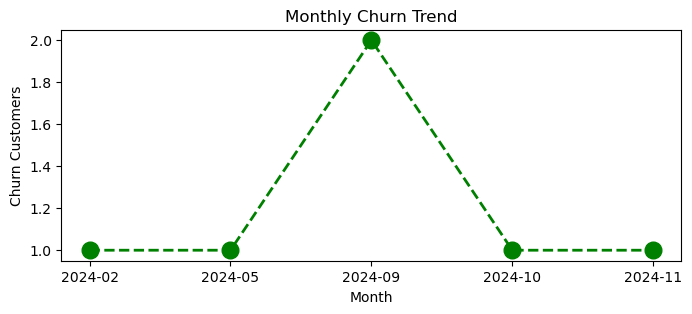

In [66]:
# Monthly churn trend (time series KPI)
df_visual['cancellation_month'] = df_visual['cancellation_date'].dt.to_period('M')

churn_trend = df_visual[df_visual['churn_flag'] == 1 ].groupby('cancellation_month').size()
plt.figure(figsize = (8,3))
plt.plot(churn_trend.index.astype(str) , churn_trend.values ,color='green', marker='o', linestyle='dashed',linewidth=2, markersize=12)

plt.title('Monthly Churn Trend')
plt.xlabel('Month')
plt.ylabel('Churn Customers')
plt.show()


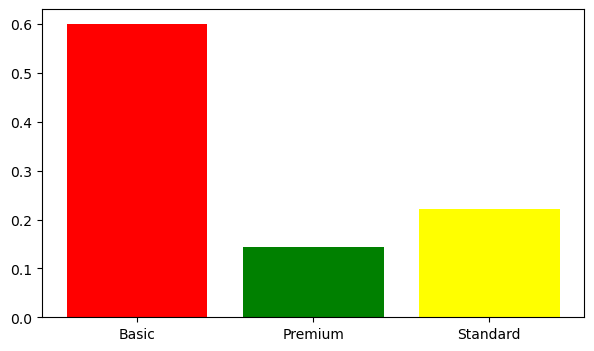

In [67]:
# Churn by plan type

churn_plan = df_visual.groupby('plan_type')['churn_flag'].mean()
plt.figure(figsize =(7, 4))
colors = ['red', 'green' , 'yellow']
plt.bar(churn_plan.index , churn_plan.values , color = colors)
plt.show()

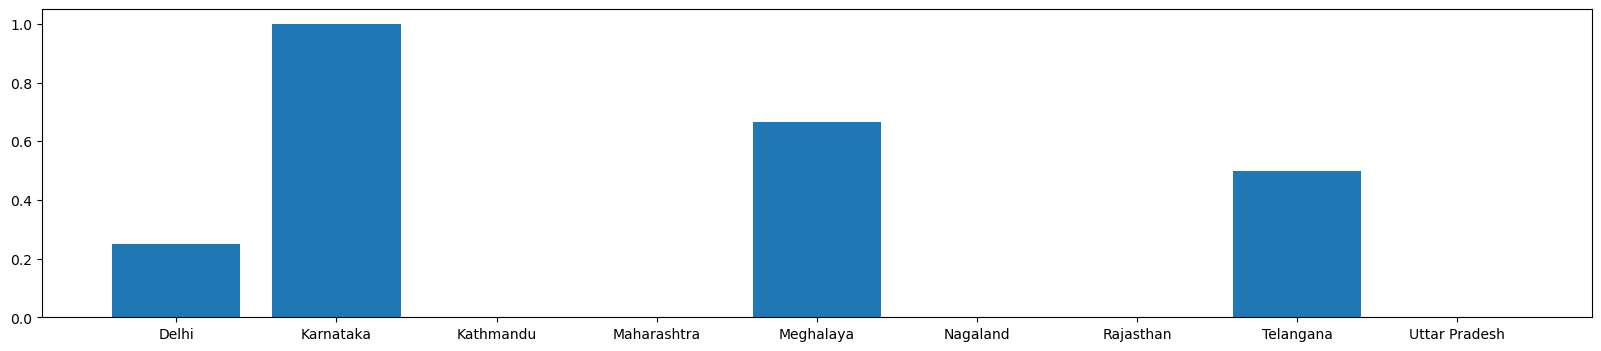

In [68]:
# churn by state 

churn_state = df_visual.groupby('state')['churn_flag'].mean()
plt.figure( figsize =(20,4))
plt.bar(churn_state.index , churn_state.values)
plt.show()

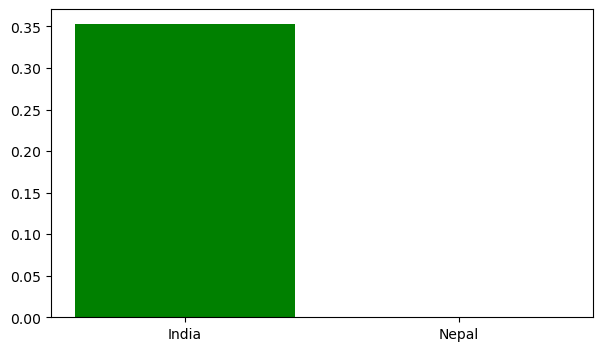

In [69]:
# churn by country

churn_by_country = df_visual.groupby('country')['churn_flag'].mean()
plt.figure(figsize =(7,4))
plt.bar(churn_by_country.index , churn_by_country.values , color = "green")
plt.show()

In [70]:
df_visual.columns

Index(['customerid', 'subscription_start_date', 'subscription_type',
       'renewal_date', 'plan_type', 'contract_type', 'cancellation_date',
       'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score',
       'churn_flag', 'customer_name', 'country', 'state', 'gender', 'dob',
       'complaint_date', 'escalations', 'csat_score', 'complaint_count',
       'tenure_days', 'churn_risk', 'cancellation_month'],
      dtype='object')

## Visualization using seaborn

In [71]:
# encoding - convert string tto numeric values so that we can find corr between features
df_visual.columns

Index(['customerid', 'subscription_start_date', 'subscription_type',
       'renewal_date', 'plan_type', 'contract_type', 'cancellation_date',
       'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score',
       'churn_flag', 'customer_name', 'country', 'state', 'gender', 'dob',
       'complaint_date', 'escalations', 'csat_score', 'complaint_count',
       'tenure_days', 'churn_risk', 'cancellation_month'],
      dtype='object')

In [72]:
df_visual[['plan_type', 'contract_type','churn_score','churn_flag','escalations']].head()

,plan_type,contract_type,churn_score,churn_flag,escalations
0,Standard,Annual,12,0,NaN
1,Premium,Annual,91,1,Y
2,Basic,Monthly,34,0,NaN
3,Premium,Annual,8,0,NaN
4,Standard,Monthly,88,1,Y


In [73]:
df_visual['escalations'].isna().sum()

np.int64(14)

In [74]:
df_visual['escalations'] = df_visual['escalations'].fillna('N')

In [75]:
df_visual['escalations'].value_counts()

escalations
N    17
Y     4
Name: count, dtype: int64

In [76]:
df_visual['escalations'] = df_visual['escalations'].map({
    'Y': 1,
    'N': 0
})

In [77]:
# wrong Approach 
df_encoded = df_visual[['plan_type', 'contract_type', 'churn_score',
                        'churn_flag', 'churn_risk', 'escalations']].copy()

categorical_cols = ['plan_type', 'contract_type', 'churn_risk',
                    'churn_flag']

for col in categorical_cols:
    df_encoded[col] = df_encoded[col].astype('category').cat.codes

In [78]:
df_encoded.head()

,plan_type,contract_type,churn_score,churn_flag,churn_risk,escalations
0,2,0,12,0,1,0
1,1,0,91,1,0,1
2,0,1,34,0,1,0
3,1,0,8,0,1,0
4,2,1,88,1,0,1


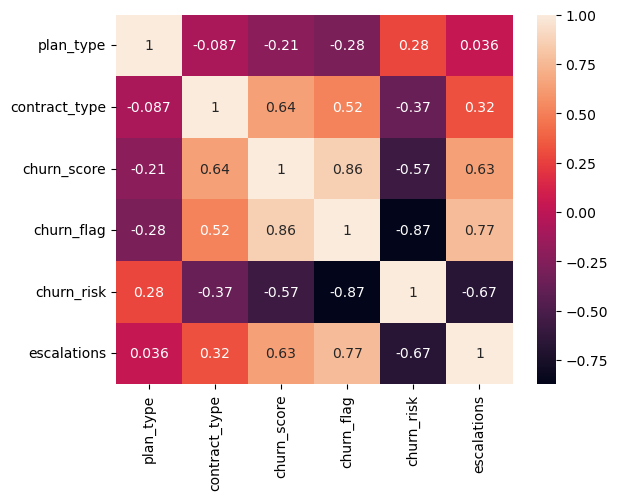

In [79]:

sns.heatmap(df_encoded.corr(numeric_only=True), annot=True)
plt.show()

In [80]:
df_encoded = df_visual[['plan_type', 'contract_type', 'churn_score',
                        'churn_flag', 'churn_risk', 'escalations']].copy()

order_mappings = {
    'plan_type': ['Basic', 'Standard', 'Premium'],
    'contract_type': ['Monthly', 'Annual'],
    'churn_risk': ['low', 'medium', 'high']
}

for col, order in order_mappings.items():
    df_encoded[col] = pd.Categorical(
        df_encoded[col],
        categories=order,
        ordered=True
    ).codes

In [81]:
df_encoded.head()

,plan_type,contract_type,churn_score,churn_flag,churn_risk,escalations
0,1,1,12,0,-1,0
1,2,1,91,1,-1,1
2,0,0,34,0,-1,0
3,2,1,8,0,-1,0
4,1,0,88,1,-1,1


In [82]:
df_visual['churn_risk'].value_counts(dropna=False)

churn_risk
Low       13
High       6
Medium     2
Name: count, dtype: int64

In [83]:
df_encoded['churn_risk'] = (
    df_visual['churn_risk']
    .astype(str)
    .str.strip()
    .str.lower()
)

In [84]:
df_encoded['churn_risk'] = pd.Categorical(
    df_encoded['churn_risk'],
    categories=['low', 'medium', 'high'],
    ordered=True
).codes

In [85]:
df_encoded['churn_risk'].value_counts()

churn_risk
0    13
2     6
1     2
Name: count, dtype: int64

In [86]:
df_encoded.head()

,plan_type,contract_type,churn_score,churn_flag,churn_risk,escalations
0,1,1,12,0,0,0
1,2,1,91,1,2,1
2,0,0,34,0,0,0
3,2,1,8,0,0,0
4,1,0,88,1,2,1


<Axes: >

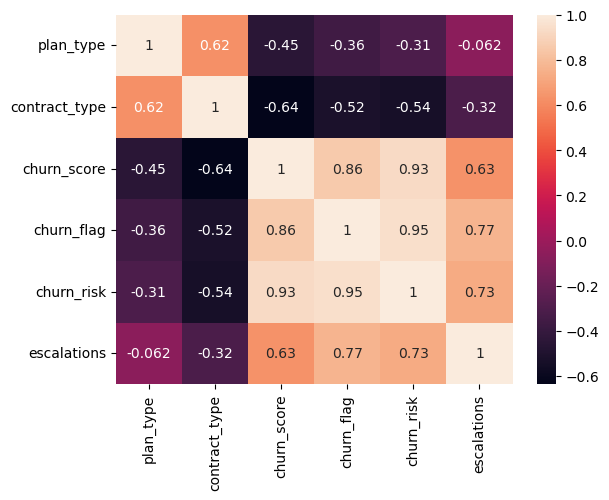

In [87]:
# HeatMap (correlation matrix)

sns.heatmap(df_encoded.corr(), annot=True)

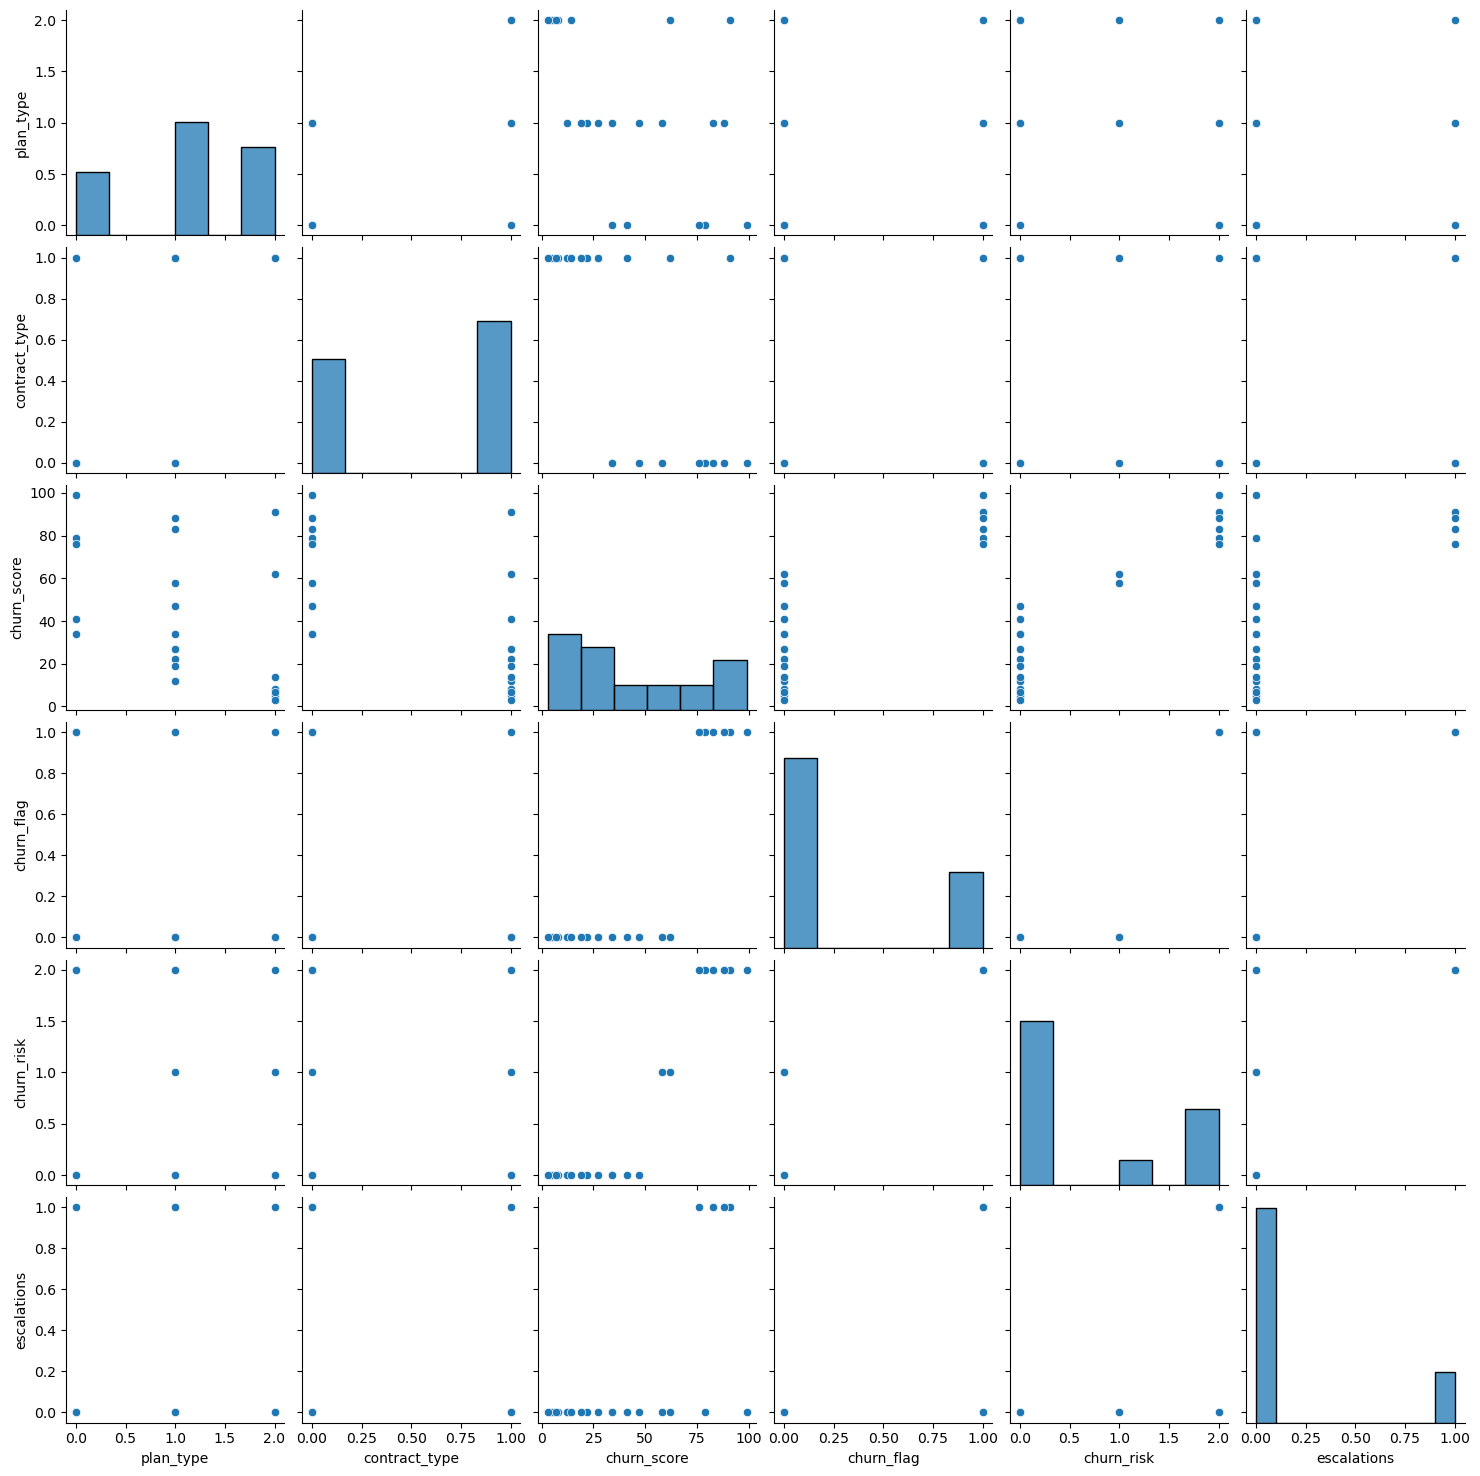

In [88]:
 # pairplot
sns.pairplot(df_encoded)

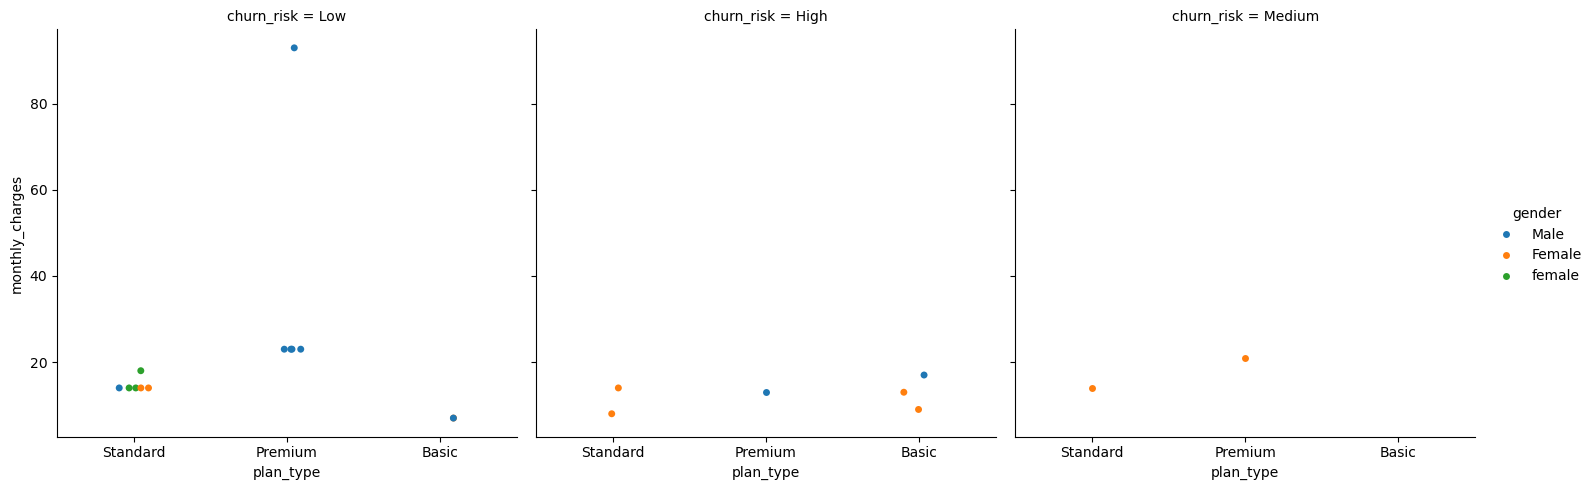

In [89]:
#catplot/facegrid plot 

sns.catplot(data=df_visual,
            x='plan_type',
            y= 'monthly_charges',
            hue ='gender',
            col='churn_risk')

In [90]:
df_visual.columns

Index(['customerid', 'subscription_start_date', 'subscription_type',
       'renewal_date', 'plan_type', 'contract_type', 'cancellation_date',
       'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score',
       'churn_flag', 'customer_name', 'country', 'state', 'gender', 'dob',
       'complaint_date', 'escalations', 'csat_score', 'complaint_count',
       'tenure_days', 'churn_risk', 'cancellation_month'],
      dtype='object')

In [93]:
#Pivot Table
pd.pivot_table (
    df_visual,
    index='plan_type',
    values='churn_flag',
    aggfunc  = 'mean',
).reset_index()

,plan_type,churn_flag
0,Basic,0.600000
1,Premium,0.142857
2,Standard,0.222222


In [96]:
pd.pivot_table(
    df_visual,
    index='plan_type',
    values = ['customerid','monthly_charges','churn_flag'],
    
    aggfunc = {'customerid' : 'nunique'
               ,'monthly_charges':'sum'
               ,'churn_flag':'mean'
    
}).reset_index()

,plan_type,churn_flag,customerid,monthly_charges
0,Basic,0.600000,5,52.95
1,Premium,0.142857,7,218.93
2,Standard,0.222222,9,123.91


# Working with SQL in python (pandas)

In [153]:
import sqlite3

# Create database
conn = sqlite3.connect('test_database.sqlite')

# Create table
conn.execute("""
CREATE TABLE employe (
    name TEXT,
    country TEXT,
    budget INTEGER
)
""")

# Save changes
conn.commit()



OperationalError: table employe already exists

In [154]:
# Insert data

cursor = conn.cursor()

# Insert records into the emp table
cursor.execute("""
    INSERT INTO employe (name, country, budget)
    VALUES
    ('MADHAV', 'INDIA', 5000),
    ('JAYANTI', 'JAPAN', 2500),
    ('BHAVY', 'INDIA', 3500)
""")

# Commit and save
conn.commit()

In [157]:
# check inserted data in table

query = "SELECT * FROM employe"

df_result = pd.read_sql(query, conn)

df_result.head()

,name,country,budget
0,MADHAV,INDIA,5000
1,JAYANTI,JAPAN,2500
2,BHAVY,INDIA,3500


In [158]:
# aggrigate
query = """  select country , sum(budget) as Total_budget
from employe
group by country 
"""

df_agg = pd.read_sql(query, conn)
df_agg

,country,Total_budget
0,INDIA,8500
1,JAPAN,2500


In [159]:
# always close the conn with database once the task is over 
conn.close()